In [ ]:
import torch
from d2l import torch as d2l
from torch import nn
import torch.nn.functional as F
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

import math

In [ ]:
batch_size_out=25
num_steps_out=35
num_hiddens_out=256

In [ ]:
data=d2l.TimeMachine(batch_size_out,num_steps_out)
train_iter=data.get_dataloader(False)
vocab=data.vocab

In [ ]:
rnn_layer=nn.RNN(len(vocab),num_hiddens_out)
class RNN_Model(nn.Module):
    def __init__(self,vocab_size,num_hiddens):
        super().__init__()
        self.rnn=nn.RNN(vocab_size,num_hiddens)
        self.vocab_size=vocab_size
        self.num_hiddens=num_hiddens
        self.linear=nn.Linear(num_hiddens,vocab_size)

    def forward(self,inputs,state):
        X=F.one_hot(inputs.T.long(),self.vocab_size)
        X=X.to(torch.float32)
        Y,state=self.rnn(X,state)
        outputs=self.linear(Y.reshape((-1,Y.shape[-1])))
        return outputs,state

    def begin_state(self,device,batch_size):
        return torch.zeros((self.rnn.num_layers,batch_size,self.num_hiddens),device=device)

state = torch.zeros((1, batch_size_out, num_hiddens_out))
X = torch.rand(size=(num_steps_out, batch_size_out, len(vocab))) 
Y, state_new = rnn_layer(X, state) 
Y.shape, state_new.shape



In [ ]:
def predict_full(prefix,vocab,target_length,net,device):
    state=net.begin_state(device,1)
    outputs=[vocab[prefix[0]]]
    #prewarm
    for x in prefix[1:]:
        _,state=net(torch.tensor(outputs[-1],device=device).reshape((1,1)),state)
        outputs.append(vocab[x])

    #pred
    for _ in range(target_length):
        y,state=net(torch.tensor(outputs[-1],device=device).reshape(1,1),state)
        outputs.append(int(torch.argmax(y,dim=1).reshape(1)))

    return ''.join([vocab.idx_to_token[idx] for idx in outputs])

In [ ]:
device = d2l.try_gpu() 
net = RNN_Model(vocab_size=len(vocab),num_hiddens=num_hiddens_out) 
net = net.to(device) 
predict_full('time traveller', vocab, 10, net,device)

In [ ]:
def gradient_clip(net,theta):
    if isinstance(net,torch.nn.Module):
        params=[param for param in net.parameters() if param.requires_grad]
    else: 
        params=net.params
    norm = torch.sqrt(sum(torch.sum((p.grad ** 2)) for p in params)) 
    if norm > theta:  
        for param in params:  
            param.grad[:] *= theta / norm

In [ ]:
def train_epoch(net,loss,updater,device,use_random_iter,train_iter,batch_size,theta):
    states, timer = None, d2l.Timer() 
    metric = d2l.Accumulator(2) # 训练损失之和,词元数量
    for X,Y in train_iter:
        if states==None or use_random_iter:
            states=net.begin_state(device,batch_size)
        else:
            if isinstance(states, tuple):
                states = tuple(s.detach() for s in states)   # ✅ tuple
            else:
                states = states.detach()   
        y=Y.T.reshape(-1)
        X=X.to(device)
        y=y.to(device)
        y_hat,states=net(X,states)
        l = loss(y_hat,y.long()).mean()
        if isinstance(updater,torch.optim.Optimizer):
            updater.zero_grad()
            l.backward()
            gradient_clip(net,theta)
            updater.step()
        else:
            l.backward()
            gradient_clip(net,theta)
            updater(batch_size=1)
        metric.add(l * y.numel(), y.numel()) 
    return math.exp(metric[0] / metric[1]), metric[1] / timer.stop()  
     



In [86]:
def train_ch8(net, train_iter, vocab, lr, num_epochs, batch_size,device,  use_random_iter=False):
    """训练模型(定义见第8章)""" 
    loss = torch.nn.CrossEntropyLoss() 
    animator = d2l.Animator(xlabel='epoch', ylabel='perplexity',
                            legend=['train'], xlim=[10, num_epochs]) 
     # 初始化 
    if isinstance(net, torch.nn.Module):  
        updater = torch.optim.SGD(net.parameters(), lr) 
    else:  
        updater = lambda batch_size: d2l.sgd(net.params, lr, batch_size)  
    predict_f = lambda prefix: predict_full(prefix, vocab,50, net, device) 
    # 训练和预测 
    for epoch in range(num_epochs):  
        ppl, speed = train_epoch(net,loss,updater,device,use_random_iter, train_iter,batch_size,1) 
        if (epoch + 1) % 4 == 0:  
            print(predict_full('time traveller' ,vocab,50, net, device)) 
            animator.add(epoch + 1, [ppl]) 
    print(f'困惑度 {ppl:.1f}, {speed:.1f} 词元/秒 {str(device)}') 
    print(predict_full('time traveller' ,vocab,50, net, device)) 
    print(predict_full('traveller' ,vocab,50, net, device))

困惑度 1.2, 243519.7 词元/秒 cuda:0
time traveller and the fireplace filby sat bel it is my plan for
traveller presently i am obe the spoke of a wheel spinning 


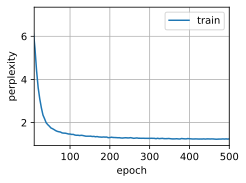

In [88]:
num_epochs, lr = 500, 0.55
device=d2l.try_gpu(0)
net=RNN_Model(len(vocab),num_hiddens_out)
net=net.to(device)
train_ch8(net, train_iter, vocab, lr, num_epochs,batch_size_out, device)